# Covertype — Experimentación y registro con MLflow

Este notebook implementa el flujo completo de entrenamiento:

1. Lectura de `covertype.csv`.
2. Validación y normalización básica del dataset.
3. Persistencia en PostgreSQL en `raw.covertype` y `processed.covertype`.
4. Separación estratificada `train/test`.
5. Ejecución de **20+ runs** en MLflow:
   - baselines;
   - variaciones manuales de hiperparámetros;
   - varios algoritmos;
   - un experimento con `GridSearchCV`.
6. Registro de parámetros, métricas y modelos como artifacts de cada run.
7. Comparación de resultados usando `f1_macro` como métrica principal.
8. Registro de los mejores candidatos en MLflow Model Registry.
9. Asignación del alias `champion` al mejor modelo.

> El preprocesamiento que afecte al modelo se encapsula dentro de `Pipeline` cuando es necesario, evitando fuga de información entre entrenamiento y prueba.


In [1]:
from __future__ import annotations

import json
import os
import re
import tempfile
from pathlib import Path
from typing import Any
import gc

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow import MlflowClient
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sqlalchemy import create_engine, text
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = Path("/workspace/data/covertype.csv")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://mlflow:5000")
EXPERIMENT_NAME = "covertype_classification"
REGISTERED_MODEL_NAME = os.getenv(
    "MLFLOW_MODEL_NAME",
    "covertype_classifier",
)
MODEL_ALIAS = os.getenv("MLFLOW_MODEL_ALIAS", "champion")

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

print(f"MLflow: {MLFLOW_TRACKING_URI}")
print(f"Dataset: {DATA_PATH}")


MLflow: http://mlflow:5000
Dataset: /workspace/data/covertype.csv


## 1. Funciones auxiliares

In [2]:
def normalize_column_name(name: str) -> str:
    normalized = name.strip().lower()
    normalized = re.sub(r"[^a-z0-9]+", "_", normalized)
    return normalized.strip("_")


def detect_target_column(columns: list[str]) -> str:
    candidates = {
        "cover_type",
        "covertype",
        "cover_type_class",
        "class",
        "label",
        "target",
    }

    normalized_map = {
        normalize_column_name(column): column
        for column in columns
    }

    for candidate in candidates:
        if candidate in normalized_map:
            return normalized_map[candidate]

    raise ValueError(
        "No se pudo identificar la variable objetivo. "
        f"Columnas disponibles: {columns}"
    )


def build_database_url() -> str:
    user = os.environ["DATA_DB_USER"]
    password = os.environ["DATA_DB_PASSWORD"]
    host = os.getenv("DATA_DB_HOST", "postgres-data")
    port = os.getenv("DATA_DB_PORT", "5432")
    database = os.environ["DATA_DB_NAME"]

    return (
        f"postgresql+psycopg://{user}:{password}"
        f"@{host}:{port}/{database}"
    )


def calculate_metrics(
    y_true: pd.Series,
    y_pred: np.ndarray,
) -> dict[str, float]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision_macro": float(
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "recall_macro": float(
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_macro": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_weighted": float(
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0,
            )
        ),
    }


def log_evaluation_artifacts(
    y_true: pd.Series,
    y_pred: np.ndarray,
    labels: list[Any],
) -> None:
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0,
    )

    with tempfile.TemporaryDirectory() as tmp_dir:
        tmp_path = Path(tmp_dir)

        report_path = tmp_path / "classification_report.json"
        report_path.write_text(
            json.dumps(report, indent=2),
            encoding="utf-8",
        )
        mlflow.log_artifact(
            str(report_path),
            artifact_path="evaluation",
        )

        fig, ax = plt.subplots(figsize=(9, 8))
        ConfusionMatrixDisplay.from_predictions(
            y_true,
            y_pred,
            labels=labels,
            ax=ax,
            colorbar=False,
        )
        ax.set_title("Confusion matrix")
        fig.tight_layout()

        matrix_path = tmp_path / "confusion_matrix.png"
        fig.savefig(matrix_path, dpi=150, bbox_inches="tight")
        plt.close(fig)

        mlflow.log_artifact(
            str(matrix_path),
            artifact_path="evaluation",
        )


## 2. Carga y validación del dataset

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo esperado: {DATA_PATH}"
    )

raw_df = pd.read_csv(DATA_PATH)

print(f"Filas: {raw_df.shape[0]:,}")
print(f"Columnas: {raw_df.shape[1]}")
display(raw_df.head())


Filas: 581,012
Columnas: 13


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area,Soil_Type,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,Rawah,C7745,4
1,2590,56,2,212,-6,390,220,235,151,6225,Rawah,C7745,4
2,2804,139,9,268,65,3180,234,238,135,6121,Rawah,C4744,1
3,2785,155,18,242,118,3090,238,238,122,6211,Rawah,C7746,1
4,2595,45,2,153,-1,391,220,234,150,6172,Rawah,C7745,4


In [4]:
raw_df["Soil_Type"].unique()

<ArrowStringArray>
['C7745', 'C4744', 'C7746', 'C6731', 'C6101', 'C7102', 'C7700', 'C7202',
 'C8776', 'C7101', 'C3502', 'C7201', 'C8772', 'C4201', 'C8771', 'C7757',
 'C7755', 'C7756', 'C4704', 'C4703', 'C2706', 'C7710', 'C2705', 'C2702',
 'C4758', 'C2703', 'C6102', 'C2704', 'C7790', 'C2717', 'C5101', 'C8708',
 'C8703', 'C8707', 'C7103', 'C7702', 'C7709', 'C7701', 'C3501', 'C5151']
Length: 40, dtype: str

In [5]:
if raw_df.empty:
    raise ValueError("El dataset está vacío.")

if raw_df.columns.duplicated().any():
    duplicates = raw_df.columns[raw_df.columns.duplicated()].tolist()
    raise ValueError(f"Existen columnas duplicadas: {duplicates}")

target_original = detect_target_column(raw_df.columns.tolist())

column_mapping = {
    column: normalize_column_name(column)
    for column in raw_df.columns
}

raw_db_df = raw_df.rename(columns=column_mapping).copy()
target_column = column_mapping[target_original]

print(f"Variable objetivo detectada: {target_original!r}")
print(f"Nombre normalizado: {target_column!r}")
print()
print(raw_db_df.dtypes.value_counts())
print()
print("Distribución de la variable objetivo:")
display(
    raw_db_df[target_column]
    .value_counts(dropna=False)
    .sort_index()
    .rename("count")
    .to_frame()
)


Variable objetivo detectada: 'Cover_Type'
Nombre normalizado: 'cover_type'

int64    11
str       2
Name: count, dtype: int64

Distribución de la variable objetivo:


,count
cover_type,
0,211840
1,283301
2,35754
3,2747
4,9493
5,17367
6,20510


## 3. Persistencia de datos crudos

La tabla `raw.covertype` representa el dataset de entrada.  
El notebook crea el esquema si aún no existe y reemplaza la tabla para hacer la ejecución reproducible dentro de este entorno de laboratorio.


In [6]:
engine = create_engine(
    build_database_url(),
    pool_pre_ping=True,
)

with engine.begin() as connection:
    connection.execute(text("CREATE SCHEMA IF NOT EXISTS raw"))
    connection.execute(text("CREATE SCHEMA IF NOT EXISTS processed"))

MAX_PARAMETERS = 60_000

chunksize = max(1, MAX_PARAMETERS // len(raw_db_df.columns))

print(f"Número de columnas: {len(raw_db_df.columns)}")
print(f"Chunksize utilizado: {chunksize}")

raw_db_df.to_sql(
    name="covertype",
    con=engine,
    schema="raw",
    if_exists="replace",
    index=False,
    chunksize=chunksize,
    method="multi",
)

print(
    f"raw.covertype cargada: "
    f"{len(raw_db_df):,} registros"
)


Número de columnas: 13
Chunksize utilizado: 4615
raw.covertype cargada: 581,012 registros


## 4. Preprocesamiento

Se mantiene deliberadamente simple porque Covertype es un dataset estructurado y predominantemente numérico.

Se realizan únicamente transformaciones de calidad de datos:

- nombres de columnas normalizados;
- eliminación de duplicados exactos;
- eliminación de registros sin variable objetivo;
- validación de valores faltantes;
- validación de que las variables predictoras sean numéricas.

El escalamiento no se realiza globalmente: cuando un algoritmo lo necesita, se incluye dentro de su `Pipeline`.


In [7]:
processed_df = raw_db_df.copy()

rows_before = len(processed_df)
processed_df = processed_df.drop_duplicates().copy()
duplicates_removed = rows_before - len(processed_df)

missing_target = int(processed_df[target_column].isna().sum())
processed_df = processed_df.dropna(subset=[target_column]).copy()

feature_columns = [
    column
    for column in processed_df.columns
    if column != target_column
]

categorical_columns = [
    column
    for column in feature_columns
    if not pd.api.types.is_numeric_dtype(processed_df[column])
]

numeric_columns = [
    column
    for column in feature_columns
    if pd.api.types.is_numeric_dtype(processed_df[column])
]

missing_features = int(
    processed_df[feature_columns].isna().sum().sum()
)

if missing_features:
    raise ValueError(
        "Se encontraron valores faltantes en las variables "
        f"predictoras: {missing_features}"
    )

print(f"Duplicados eliminados: {duplicates_removed:,}")
print(f"Registros sin target eliminados: {missing_target:,}")
print(f"Filas procesadas: {len(processed_df):,}")
print(f"Features totales: {len(feature_columns)}")
print(f"Features numéricas: {len(numeric_columns)}")
print(f"Features categóricas: {len(categorical_columns)}")
print(f"Columnas categóricas: {categorical_columns}")

Duplicados eliminados: 0
Registros sin target eliminados: 0
Filas procesadas: 581,012
Features totales: 12
Features numéricas: 10
Features categóricas: 2
Columnas categóricas: ['wilderness_area', 'soil_type']


In [8]:
processed_chunksize = max(1, MAX_PARAMETERS // len(processed_df.columns))

processed_df.to_sql(
    name="covertype",
    con=engine,
    schema="processed",
    if_exists="replace",
    index=False,
    chunksize=processed_chunksize,
    method="multi",
)

with engine.connect() as connection:
    raw_count = connection.execute(
        text("SELECT COUNT(*) FROM raw.covertype")
    ).scalar_one()

    processed_count = connection.execute(
        text("SELECT COUNT(*) FROM processed.covertype")
    ).scalar_one()

print(f"raw.covertype: {raw_count:,}")
print(f"processed.covertype: {processed_count:,}")


raw.covertype: 581,012
processed.covertype: 581,012


## 5. División de entrenamiento y prueba

In [9]:
X = processed_df[feature_columns].copy()
y = processed_df[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

labels = sorted(y.unique().tolist())

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"Clases: {labels}")


Train: (464809, 12)
Test:  (116203, 12)
Clases: [0, 1, 2, 3, 4, 5, 6]


Definimos el pipeline para la transformación de las columnas.

In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_columns,
        ),
    ],
    remainder="passthrough",
)

In [11]:
preprocessor_scaled = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_columns,
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_columns,
        ),
    ]
)

## 6. Configuración del experimento MLflow

Cada configuración representa un **run independiente**. No se usa un único grid masivo como sustituto de la experimentación: se combinan baselines, cambios manuales de hiperparámetros y diferentes familias de modelos.


In [23]:
experiment = mlflow.set_experiment(EXPERIMENT_NAME)

print(f"Experiment ID: {experiment.experiment_id}")
print(f"Experiment name: {EXPERIMENT_NAME}")


2026/10/03 04:18:50 INFO mlflow.tracking.fluent: Experiment with name 'covertype_classification' does not exist. Creating a new experiment.


Experiment ID: 1
Experiment name: covertype_classification


In [12]:
experiment_specs = [
    {
        "experiment_name": "exp_01_dt_baseline",
        "run_name": "dt_baseline",
        "family": "decision_tree",
        "type": "baseline",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
    {
        "experiment_name": "exp_02_dt_depth_8",
        "run_name": "dt_depth_8",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=8,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
    {
        "experiment_name": "exp_03_dt_depth_12",
        "run_name": "dt_depth_12",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=12,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ), 
    },
    {
        "experiment_name": "exp_04_dt_depth_20",
        "run_name": "dt_depth_20",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=20,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
    {
        "experiment_name": "exp_05_dt_leaf_5",
        "run_name": "dt_leaf_5",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        min_samples_leaf=5,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
    {
        "experiment_name": "exp_06_dt_entropy",
        "run_name": "entropy",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        criterion="entropy",
                        max_depth=20,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
    {
        "experiment_name": "exp_07_rf_baseline",
        "run_name": "rf_baseline",
        "family": "random_forest",
        "type": "baseline",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=100,
                        n_jobs=-1,
                        random_state=RANDOM_STATE,
                        ),
                    ),
                ]
        ),
    },
  {
        "experiment_name": "exp_08_dt_depth_5",
        "run_name": "dt_depth_5",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=5,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_09_dt_depth_10",
        "run_name": "dt_depth_10",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=10,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_10_dt_depth_15",
        "run_name": "dt_depth_15",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=15,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_11_dt_depth_25",
        "run_name": "dt_depth_25",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=25,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_12_dt_leaf_2",
        "run_name": "dt_leaf_2",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        min_samples_leaf=2,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_13_dt_leaf_10",
        "run_name": "dt_leaf_10",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        min_samples_leaf=10,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_14_dt_split_5",
        "run_name": "dt_split_5",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        min_samples_split=5,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_15_dt_split_20",
        "run_name": "dt_split_20",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        min_samples_split=20,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_16_dt_entropy_depth_12",
        "run_name": "dt_entropy_depth_12",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        criterion="entropy",
                        max_depth=12,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_17_dt_entropy_depth_20",
        "run_name": "dt_entropy_depth_20",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        criterion="entropy",
                        max_depth=20,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_18_dt_log_loss",
        "run_name": "dt_log_loss",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        criterion="log_loss",
                        max_depth=20,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_19_dt_features_sqrt",
        "run_name": "dt_features_sqrt",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_features="sqrt",
                        max_depth=20,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
    {
        "experiment_name": "exp_20_dt_balanced",
        "run_name": "dt_balanced",
        "family": "decision_tree",
        "type": "manual_tuning",
        "estimator": Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    DecisionTreeClassifier(
                        class_weight="balanced",
                        max_depth=20,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
    },
]

print(f"Runs manuales configurados: {len(experiment_specs)}")


Runs manuales configurados: 20


## 7. Ejecución de los runs manuales

In [38]:
START_EXPERIMENT = 10

specs_to_run = experiment_specs[START_EXPERIMENT - 1:]

In [13]:
SKOPS_TRUSTED_TYPES = [
    "sklearn.tree._tree.Tree",
]

results: list[dict[str, Any]] = []

for index, spec in enumerate(experiment_specs , start=1):
    experiment = mlflow.set_experiment(
        spec["experiment_name"]
    )

    print(
        f"[{index:02d}/{len(experiment_specs )}] "
        f"{spec['experiment_name']}"
    )

    estimator = clone(spec["estimator"])

    with mlflow.start_run(run_name=spec["run_name"]) as run:
        mlflow.set_tags(
            {
                "model_family": spec["family"],
                "experiment_type": spec["type"],
                "dataset": "covertype",
            }
        )

        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("test_size", TEST_SIZE)
        mlflow.log_param("train_rows", len(X_train))
        mlflow.log_param("test_rows", len(X_test))
        mlflow.log_param("n_features", X_train.shape[1])

        estimator.fit(X_train, y_train)
        y_pred = estimator.predict(X_test)

        metrics = calculate_metrics(y_test, y_pred)
        mlflow.log_metrics(metrics)

        model_params = estimator.get_params(deep=True)

        safe_params = {
            key: value
            for key, value in model_params.items()
            if isinstance(value, (str, int, float, bool))
            or value is None
        }

        mlflow.log_params(safe_params)

        log_evaluation_artifacts(
            y_test,
            y_pred,
            labels,
        )

        model_info = mlflow.sklearn.log_model(
            sk_model=estimator,
            name="model",
            input_example=X_train.head(5),
            skops_trusted_types=SKOPS_TRUSTED_TYPES,
        )

        results.append(
            {
                "run_id": run.info.run_id,
                "run_name": spec["run_name"],
                "model_family": spec["family"],
                "experiment_type": spec["type"],
                "model_uri": model_info.model_uri,
                **metrics,
            }
        )
    del estimator
    del y_pred

    gc.collect()

results_df = pd.DataFrame(results)


display(
    results_df.sort_values(
        ["f1_macro", "balanced_accuracy"],
        ascending=False,
    ).reset_index(drop=True)
)


2026/10/04 05:27:58 INFO mlflow.tracking.fluent: Experiment with name 'exp_01_dt_baseline' does not exist. Creating a new experiment.


[01/20] exp_01_dt_baseline


2026/10/04 05:27:59 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/04 05:27:59 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

🏃 View run dt_baseline at: http://mlflow:5000/#/experiments/1/runs/e9199fe1e9a341ad8a72a00e384e7a9a
🧪 View experiment at: http://mlflow:5000/#/experiments/1


2026/10/04 05:28:32 INFO mlflow.tracking.fluent: Experiment with name 'exp_02_dt_depth_8' does not exist. Creating a new experiment.


...

2026/10/04 05:37:31 INFO mlflow.tracking.fluent: Experiment with name 'exp_20_dt_balanced' does not exist. Creating a new experiment.


[20/20] exp_20_dt_balanced


/workspace/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/workspace/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at i

🏃 View run dt_balanced at: http://mlflow:5000/#/experiments/20/runs/518b42c9248744d698f8de842ef26bde
🧪 View experiment at: http://mlflow:5000/#/experiments/20


,run_id,run_name,model_family,experiment_type,model_uri,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,68919b83dea845d0b120f2905277dc5c,rf_baseline,random_forest,baseline,models:/m-2b4ecf669ef34dc892cc2eade9da240a,0.954339,0.906163,0.947026,0.906163,0.924963,0.954108
1,e9199fe1e9a341ad8a72a00e384e7a9a,dt_baseline,decision_tree,baseline,models:/m-9c1b5d91c2334893857dc99cb882a1a4,0.939021,0.903956,0.904131,0.903956,0.904037,0.939014
2,3085143901c84c21ad6ffaa338e5903f,dt_split_5,decision_tree,manual_tuning,models:/m-c04b3449ad494e10aceb9862a05d726d,0.937274,0.898991,0.906954,0.898991,0.902923,0.937244
3,355dce7ba57543ad83eee0ed44a87451,dt_leaf_2,decision_tree,manual_tuning,models:/m-fcd6eae164ed475bab307de672607d1f,0.935114,0.887285,0.911885,0.887285,0.899096,0.935012
4,f6a3310434034d4599e2fbfb92b1cef9,entropy,decision_tree,manual_tuning,models:/m-1d6a30c7f11e497999ce9c7f9b52d8b8,0.913599,0.883844,0.901406,0.883844,0.892212,0.913525
5,581937a8ab58491f8e74a7b62ff4163e,dt_entropy_depth_20,decision_tree,manual_tuning,models:/m-56f58776b9e64f8d8d9a71b8bbee2502,0.913599,0.883844,0.901406,0.883844,0.892212,0.913525
6,c535214dde084624be8f203644d25dcb,dt_log_loss,decision_tree,manual_tuning,models:/m-6c50739ebe6f43fdbb1cd63d06e75b17,0.913599,0.883844,0.901406,0.883844,0.892212,0.913525
7,deabae57d79e4891b301acf309f7271b,dt_leaf_5,decision_tree,manual_tuning,models:/m-dbbf443f442d40299cad9e76e05b8195,0.929778,0.884511,0.895434,0.884511,0.889870,0.929712
8,19e6deea52b24d4995a487fa36dd85c4,dt_depth_25,decision_tree,manual_tuning,models:/m-ffb964921e3c49749eede6181365ac86,0.930923,0.882352,0.898113,0.882352,0.889781,0.930732
9,d620c922e82f470cb2a0c8a6dbee9852,dt_split_20,decision_tree,manual_tuning,models:/m-d15b10b567d745f1b8f5ac73b5b040a2,0.925923,0.878347,0.894617,0.878347,0.886200,0.925863


## 8. Comparación visual

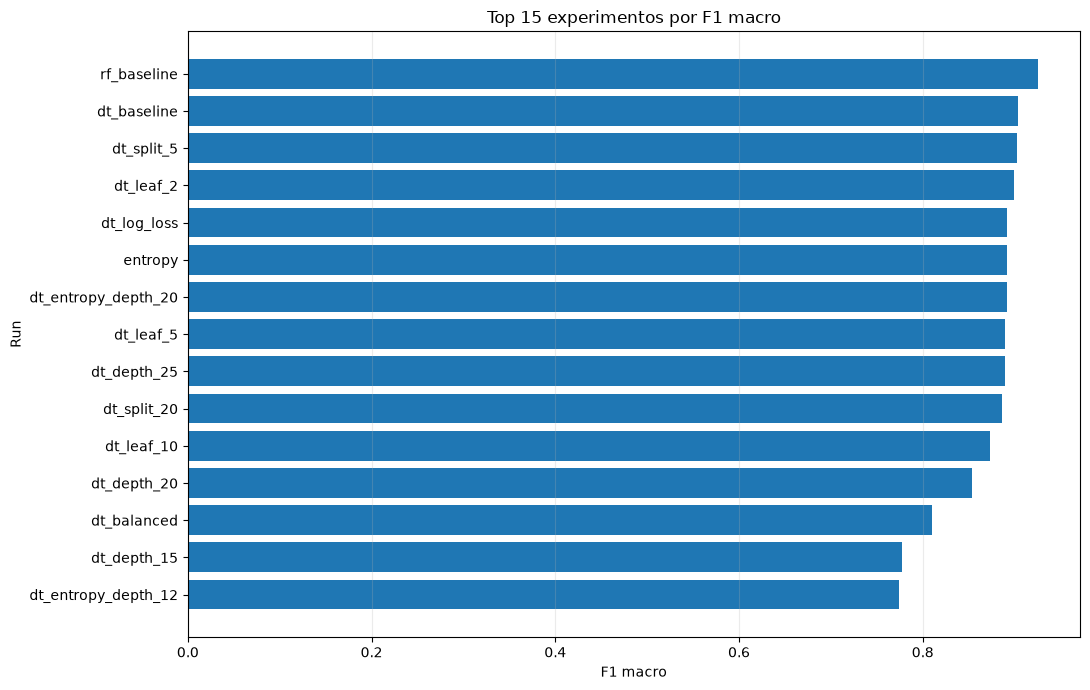

,run_name,model_family,experiment_type,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,rf_baseline,random_forest,baseline,0.954339,0.906163,0.924963,0.954108
1,dt_baseline,decision_tree,baseline,0.939021,0.903956,0.904037,0.939014
2,dt_split_5,decision_tree,manual_tuning,0.937274,0.898991,0.902923,0.937244
3,dt_leaf_2,decision_tree,manual_tuning,0.935114,0.887285,0.899096,0.935012
4,entropy,decision_tree,manual_tuning,0.913599,0.883844,0.892212,0.913525
5,dt_entropy_depth_20,decision_tree,manual_tuning,0.913599,0.883844,0.892212,0.913525
6,dt_log_loss,decision_tree,manual_tuning,0.913599,0.883844,0.892212,0.913525
7,dt_leaf_5,decision_tree,manual_tuning,0.929778,0.884511,0.889870,0.929712
8,dt_depth_25,decision_tree,manual_tuning,0.930923,0.882352,0.889781,0.930732
9,dt_split_20,decision_tree,manual_tuning,0.925923,0.878347,0.886200,0.925863


In [14]:
ranking_df = (
    results_df
    .sort_values(
        ["f1_macro", "balanced_accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

top_plot = ranking_df.head(15).sort_values("f1_macro")
ax.barh(top_plot["run_name"], top_plot["f1_macro"])
ax.set_xlabel("F1 macro")
ax.set_ylabel("Run")
ax.set_title("Top 15 experimentos por F1 macro")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

display(
    ranking_df[
        [
            "run_name",
            "model_family",
            "experiment_type",
            "accuracy",
            "balanced_accuracy",
            "f1_macro",
            "f1_weighted",
        ]
    ].head(10)
)


## 9. Selección y registro de candidatos

Se seleccionan los tres mejores runs usando:

1. `f1_macro` como métrica principal.
2. `balanced_accuracy` como criterio secundario.

Los tres se registran como versiones del mismo modelo `covertype_classifier`.  
El mejor recibe el alias `champion`.


In [15]:
top_candidates = ranking_df.head(3).copy()

display(
    top_candidates[
        [
            "run_name",
            "run_id",
            "model_family",
            "f1_macro",
            "balanced_accuracy",
        ]
    ]
)


,run_name,run_id,model_family,f1_macro,balanced_accuracy
0,rf_baseline,68919b83dea845d0b120f2905277dc5c,random_forest,0.924963,0.906163
1,dt_baseline,e9199fe1e9a341ad8a72a00e384e7a9a,decision_tree,0.904037,0.903956
2,dt_split_5,3085143901c84c21ad6ffaa338e5903f,decision_tree,0.902923,0.898991


In [16]:
client = MlflowClient()
registered_versions: list[dict[str, Any]] = []

for _, candidate in top_candidates.iterrows():
    source_uri = f"runs:/{candidate['run_id']}/model"

    model_version = mlflow.register_model(
        model_uri=source_uri,
        name=REGISTERED_MODEL_NAME,
    )

    client.set_model_version_tag(
        name=REGISTERED_MODEL_NAME,
        version=model_version.version,
        key="source_run_name",
        value=candidate["run_name"],
    )

    client.set_model_version_tag(
        name=REGISTERED_MODEL_NAME,
        version=model_version.version,
        key="f1_macro",
        value=str(candidate["f1_macro"]),
    )

    registered_versions.append(
        {
            "run_name": candidate["run_name"],
            "run_id": candidate["run_id"],
            "version": model_version.version,
            "f1_macro": candidate["f1_macro"],
        }
    )

registered_versions_df = pd.DataFrame(registered_versions)
display(registered_versions_df)


Successfully registered model 'covertype_classifier'.
2026/10/04 05:48:49 WARNING mlflow.tracking._model_registry.fluent: Run with id 68919b83dea845d0b120f2905277dc5c has no artifacts at artifact path 'model', registering model based on models:/m-2b4ecf669ef34dc892cc2eade9da240a instead
2026/10/04 05:48:49 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: covertype_classifier, version 1
Created version '1' of model 'covertype_classifier'.
Registered model 'covertype_classifier' already exists. Creating a new version of this model...
2026/10/04 05:48:49 WARNING mlflow.tracking._model_registry.fluent: Run with id e9199fe1e9a341ad8a72a00e384e7a9a has no artifacts at artifact path 'model', registering model based on models:/m-9c1b5d91c2334893857dc99cb882a1a4 instead
2026/10/04 05:48:50 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: coverty

,run_name,run_id,version,f1_macro
0,rf_baseline,68919b83dea845d0b120f2905277dc5c,1,0.924963
1,dt_baseline,e9199fe1e9a341ad8a72a00e384e7a9a,2,0.904037
2,dt_split_5,3085143901c84c21ad6ffaa338e5903f,3,0.902923


In [17]:
best_candidate = top_candidates.iloc[0]

best_version = registered_versions_df.loc[
    registered_versions_df["run_id"]
    == best_candidate["run_id"],
    "version",
].iloc[0]

client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias=MODEL_ALIAS,
    version=str(best_version),
)

print(
    f"Champion: {REGISTERED_MODEL_NAME}@{MODEL_ALIAS}"
)
print(f"Version: {best_version}")
print(f"Run: {best_candidate['run_name']}")
print(f"F1 macro: {best_candidate['f1_macro']:.6f}")


Champion: covertype_classifier@champion
Version: 1
Run: rf_baseline
F1 macro: 0.924963


## 10. Validación del modelo desde Model Registry

In [18]:
champion_uri = (
    f"models:/{REGISTERED_MODEL_NAME}@{MODEL_ALIAS}"
)

champion_model = mlflow.pyfunc.load_model(champion_uri)

sample = X_test.head(5)
sample_predictions = champion_model.predict(sample)

validation_df = sample.copy()
validation_df["prediction"] = sample_predictions
validation_df["actual"] = y_test.loc[sample.index].to_numpy()

print(f"Modelo cargado desde: {champion_uri}")
display(validation_df)


Modelo cargado desde: models:/covertype_classifier@champion


,elevation,aspect,slope,horizontal_distance_to_hydrology,vertical_distance_to_hydrology,horizontal_distance_to_roadways,hillshade_9am,hillshade_noon,hillshade_3pm,horizontal_distance_to_fire_points,wilderness_area,soil_type,prediction,actual
438215,3210,192,10,90,10,3144,219,248,162,339,Commanche,C7756,0,0
578257,2614,176,9,216,10,1556,225,245,153,912,Commanche,C2703,2,2
366706,2632,317,11,361,81,1584,192,231,179,1756,Commanche,C2703,2,1
580592,2601,147,29,306,1,470,244,222,86,1100,Commanche,C2705,2,2
540467,3173,253,19,228,48,3864,173,249,211,1376,Commanche,C8772,0,0
